# Decision tree - Classification

Article from [Kaggle](https://www.kaggle.com/code/adityakumar529/decision-tree-classification/notebook)

We will use Decision tree classification to predict the result from our modal.

Lets import the libarary needed.

## Dataset

The dataset is found on [Kaggle](https://www.kaggle.com/datasets/prathamtripathi/drug-classification)

**Context**

Since as a beginner in machine learning it would be a great opportunity to try some techniques to predict the outcome of the drugs that might be accurate for the patient.

**Content**

The target feature is

- Drug type

The feature sets are:

- Age
- Sex
- Blood Pressure Levels (BP)
- Cholesterol Levels
- Na to Potassium Ration

**Inspiration**

The main problem here in not just the feature sets and target sets but also the approach that is taken in solving these types of problems as a beginner. So best of luck.

In [6]:
import numpy as np 
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

from pathlib import Path
from urllib.request import urlretrieve

# Dataset
url = "https://huggingface.co/arminjodat/Drug_Classification/resolve/main/drug200.csv"
file_path = Path("./data/week_3_drug200.csv")

file_path.parent.mkdir(parents=True, exist_ok=True)

if not file_path.exists():
    urlretrieve(url, file_path)
    print(f"Downloaded the dataset: {file_path}")
    size_bytes = file_path.stat().st_size
    print(f"Size: {size_bytes / 1024:.2f} KiB ({size_bytes / 1024**2:.2f} MiB)")
else:
    print(f"Dataset already exists: {file_path}")

Dataset already exists: data/week_3_drug200.csv


About the data: The data is about a list of pateint having a list of disease. Through the model we will predict which drug should be provided to the patient.

In [7]:
df = pd.read_csv(file_path)
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


Lets Calculate the size of the data

In [8]:
np.size(df)

1200

Preparing the data

We will take some of the coloumns that are needed for the analaysis 

In [9]:
X = df[['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']].values
X[0:5]

array([[23, 'F', 'HIGH', 'HIGH', 25.355],
       [47, 'M', 'LOW', 'HIGH', 13.093],
       [47, 'M', 'LOW', 'HIGH', 10.114],
       [28, 'F', 'NORMAL', 'HIGH', 7.798],
       [61, 'F', 'LOW', 'HIGH', 18.043]], dtype=object)

In the above array some values in the dataset are not numeric such as Sex or BP. Unfortunately, Sklearn Decision Trees cannot handle these  variables. Hence we need to convert the same into numeric. pandas.get_dummies() Convert non-numeric variable into dummy/indicator variables.

In [10]:
from sklearn import preprocessing
le_sex = preprocessing.LabelEncoder()
le_sex.fit(['F','M'])
X[:,1] = le_sex.transform(X[:,1]) 


le_BP = preprocessing.LabelEncoder()
le_BP.fit([ 'LOW', 'NORMAL', 'HIGH'])
X[:,2] = le_BP.transform(X[:,2])


le_Chol = preprocessing.LabelEncoder()
le_Chol.fit([ 'NORMAL', 'HIGH'])
X[:,3] = le_Chol.transform(X[:,3]) 

X[0:5]


array([[23, 0, 0, 0, 25.355],
       [47, 1, 1, 0, 13.093],
       [47, 1, 1, 0, 10.114],
       [28, 0, 2, 0, 7.798],
       [61, 0, 1, 0, 18.043]], dtype=object)

Above we have changed the values into 0,1,2 as numeric.

In [11]:
#target value
y = df["Drug"]
y

0      DrugY
1      drugC
2      drugC
3      drugX
4      DrugY
       ...  
195    drugC
196    drugC
197    drugX
198    drugX
199    drugX
Name: Drug, Length: 200, dtype: object

We will be using train/test split on our decision tree. Let's import train_test_split from sklearn.cross_validation.

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=3)

We wil create test and train data

We will first create an instance of the DecisionTreeClassifier called Tree.


In [14]:
Tree = DecisionTreeClassifier(criterion="entropy", max_depth = 4)
Tree # it shows the default parameters

DecisionTreeClassifier(criterion='entropy', max_depth=4)

Let's predict it

In [15]:
Tree.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=4)

In [16]:
pred =Tree.predict(X_test)
pred

array(['DrugY', 'drugX', 'drugX', 'drugX', 'drugX', 'drugC', 'DrugY',
       'drugA', 'drugB', 'drugA', 'DrugY', 'drugA', 'DrugY', 'DrugY',
       'drugX', 'DrugY', 'drugX', 'drugX', 'drugB', 'drugX', 'drugX',
       'DrugY', 'DrugY', 'DrugY', 'drugX', 'drugB', 'DrugY', 'DrugY',
       'drugA', 'drugX', 'drugB', 'drugC', 'drugC', 'drugX', 'drugX',
       'drugC', 'DrugY', 'drugX', 'drugX', 'drugX', 'drugA', 'DrugY',
       'drugC', 'DrugY', 'drugA', 'DrugY', 'DrugY', 'DrugY', 'DrugY',
       'DrugY', 'drugB', 'drugX', 'DrugY', 'drugX', 'DrugY', 'DrugY',
       'drugA', 'drugX', 'DrugY', 'drugX'], dtype=object)

In [17]:
print (pred [0:5])
print (y_test [0:5])

['DrugY' 'drugX' 'drugX' 'drugX' 'drugX']
40     DrugY
51     drugX
139    drugX
197    drugX
170    drugX
Name: Drug, dtype: object


In [18]:
from sklearn import metrics
import matplotlib.pyplot as plt
print("DecisionTrees's Accuracy: ", metrics.accuracy_score(y_test,pred))

DecisionTrees's Accuracy:  0.9833333333333333


Create the Decision Tree and Visualize it!

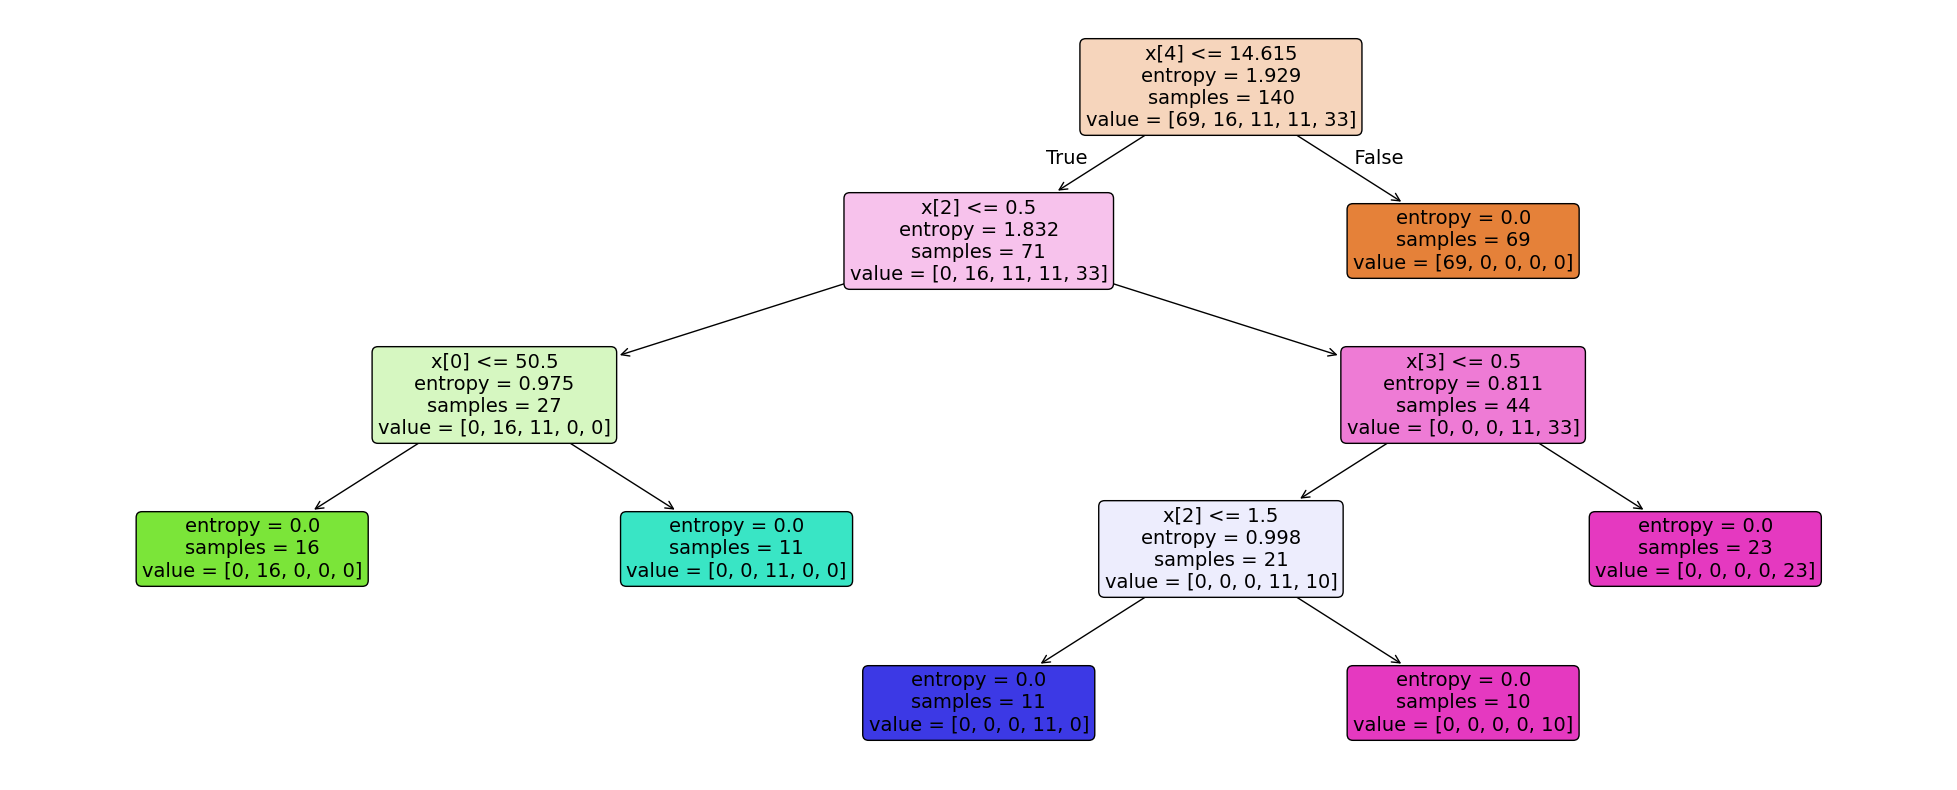

In [19]:
from sklearn import tree
plt.figure(figsize=(25,10))
tree.plot_tree(Tree,filled=True, 
              rounded=True, 
              fontsize=14);